# Laboratorio 2 · Síntesis y estacionalidad

Este notebook conecta la EDA con el siguiente laboratorio de modelado. No entrena un SARIMA ni atribuye rendimiento predictivo no evaluado.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from engine import fmt, pformat, load_dataset, run_full_analysis, descriptive_stats
from narrative import sections
r = json.loads((ROOT / 'results/analysis_summary.json').read_text(encoding='utf-8'))
h = pd.read_csv(ROOT / 'results/hourly_series.csv')
pd.options.display.float_format = lambda x: f'{x:.4f}'
def tabla(rows):
    frame = pd.DataFrame(rows)
    for col in frame:
        if col.endswith('_p') or col == 'p_value': frame[col] = frame[col].map(pformat)
    display(frame)
def apartado(i):
    title, texts = sections(r)[i-1]
    display(Markdown('## ' + title))
    for text in texts: display(Markdown(text))
def figura(name):
    display(Image(filename=str(ROOT / 'results/figures' / name), width=850))


In [2]:
apartado(7)

## 7. Síntesis y conexión con SARIMA

Para el objetivo transacciones_hora, el historial y la fase diaria son candidatos directos. ACF(1)=0.9235 y ACF(24)=0.7546. La fase 19 tiene el mayor promedio (20897.2258 transacciones); la fase menos activa promedia 40.0323. El desfase entre step y reloj civil no está documentado.

Asociación del objetivo con rezago_1: Pearson=0.9239, Spearman=0.6842, Kendall=0.5221, n=742. Estos indicadores exploran utilidad de rezagos y no equivalen a importancia predictiva validada.

Asociación del objetivo con rezago_24: Pearson=0.8046, Spearman=0.6071, Kendall=0.4685, n=719. Estos indicadores exploran utilidad de rezagos y no equivalen a importancia predictiva validada.

Ljung-Box en 24 rezagos sobre la serie original: estadístico=3775.3124, p=<0.0001. Detecta autocorrelación conjunta, no demuestra por sí solo estacionalidad. ADF en log1p(conteo): estadístico=-2.3727, p=0.1496. H0 de ADF es raíz unitaria. En este archivo no se rechaza al 5%, por lo que no se asume estacionariedad del nivel. Su decisión no descarta cambios de régimen ni sustituye el diagnóstico estacional.

Se recomienda estudiar SARIMA(p,d,q)(P,D,Q,24), compararlo con un pronóstico ingenuo estacional y evaluar ventanas de validación cronológica. Las órdenes d y D se deciden después de inspeccionar diferenciación, ACF/PACF y estacionariedad; no se eligen solo por ADF. Reservar un bloque final y medir MAE/RMSE; revisar residuos y predicciones no negativas. Este laboratorio es EDA, no presenta un SARIMA entrenado ni resultados de pronóstico inventados.

Descartar identificadores de transacción y cuentas como predictores numéricos. Conservarlos para trazabilidad. Evaluar redundancia de tipo_cuenta_destino con tipo_transaccion. Para monto, considerar log1p y estadísticas robustas; para conteo, evaluar si log1p mejora residuos. La composición por tipo o monto de la misma hora solo se conoce al cerrar esa hora: no debe entrar como predictor contemporáneo del conteo futuro. Si se usa, rezagarlo y pasar a un modelo con exógenas (SARIMAX) validando disponibilidad.

Conclusión del grupo: el volumen horario se relaciona descriptivamente con su historial y la fase temporal. La asimetría y los extremos obligan a interpretar medias y correlaciones junto con medianas, rangos y tamaños de efecto. La evidencia es propia del simulador y del periodo observado; no atribuye causas reales como promociones, demanda de clientes o fraude que no se midieron.

In [3]:
display(h.head(12))
assert h.step.diff().dropna().eq(1).all()
assert h.transacciones_hora.notna().all()
print('Frecuencia horaria regular verificada')

,step,transacciones_hora,monto_total,monto_promedio,monto_mediano,hora_dia
0,1,2708,285429181.1500,105402.2087,10286.1700,1
1,2,1014,85921604.0200,84735.3097,10522.7750,2
2,3,552,43293884.4200,78430.9500,14091.9800,3
3,4,565,72910028.5700,129044.2984,7800.5500,4
4,5,665,45548089.7500,68493.3680,6902.5200,5
5,6,1660,164310551.2200,98982.2598,17964.3550,6
6,7,6837,832930814.2400,121826.9437,13021.4300,7
7,8,21097,3439602407.3500,163037.5128,40359.1800,8
8,9,37628,7008379239.4300,186254.3648,75208.2400,9
9,10,35991,7124214893.7100,197944.3442,76649.5200,10


Frecuencia horaria regular verificada


In [4]:
from statsmodels.tsa.stattools import acf
correlations=acf(h.transacciones_hora.astype(float),nlags=72,fft=True)
assert np.isclose(correlations[24], r['seasonality']['acf_lag_24'])
print('ACF(1):',fmt(correlations[1]),'ACF(24):',fmt(correlations[24]))
tabla(r['seasonality']['lag_target_correlations'])
display(r['seasonality']['adf_log1p'])

ACF(1): 0.9235 ACF(24): 0.7546


,estado,left,right,n,alcance,covarianza_muestral,pearson_coef,pearson_p,spearman_coef,spearman_p,kendall_coef,kendall_p
0,calculado,rezago_1,transacciones_hora,742,"Horas; p nominal, autocorrelación no implica c...",165774901.6596,0.9239,<0.0001,0.6842,<0.0001,0.5221,<0.0001
1,calculado,rezago_24,transacciones_hora,719,"Horas; p nominal, autocorrelación no implica c...",139935688.7767,0.8046,<0.0001,0.6071,<0.0001,0.4685,<0.0001


{'statistic': -2.3726907691113874,
 'p_value': 0.14959303302598725,
 'used_lags': 20}

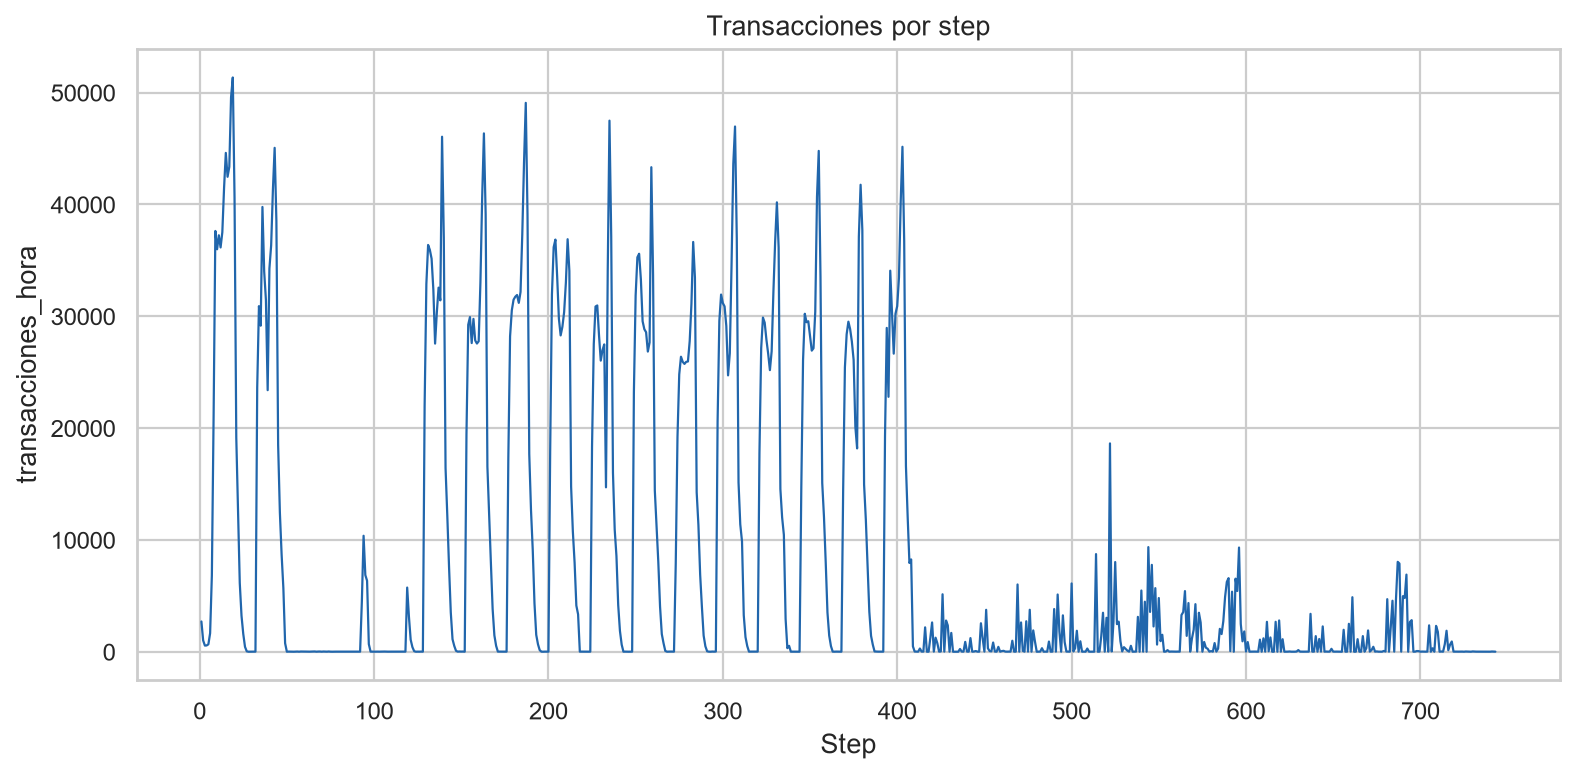

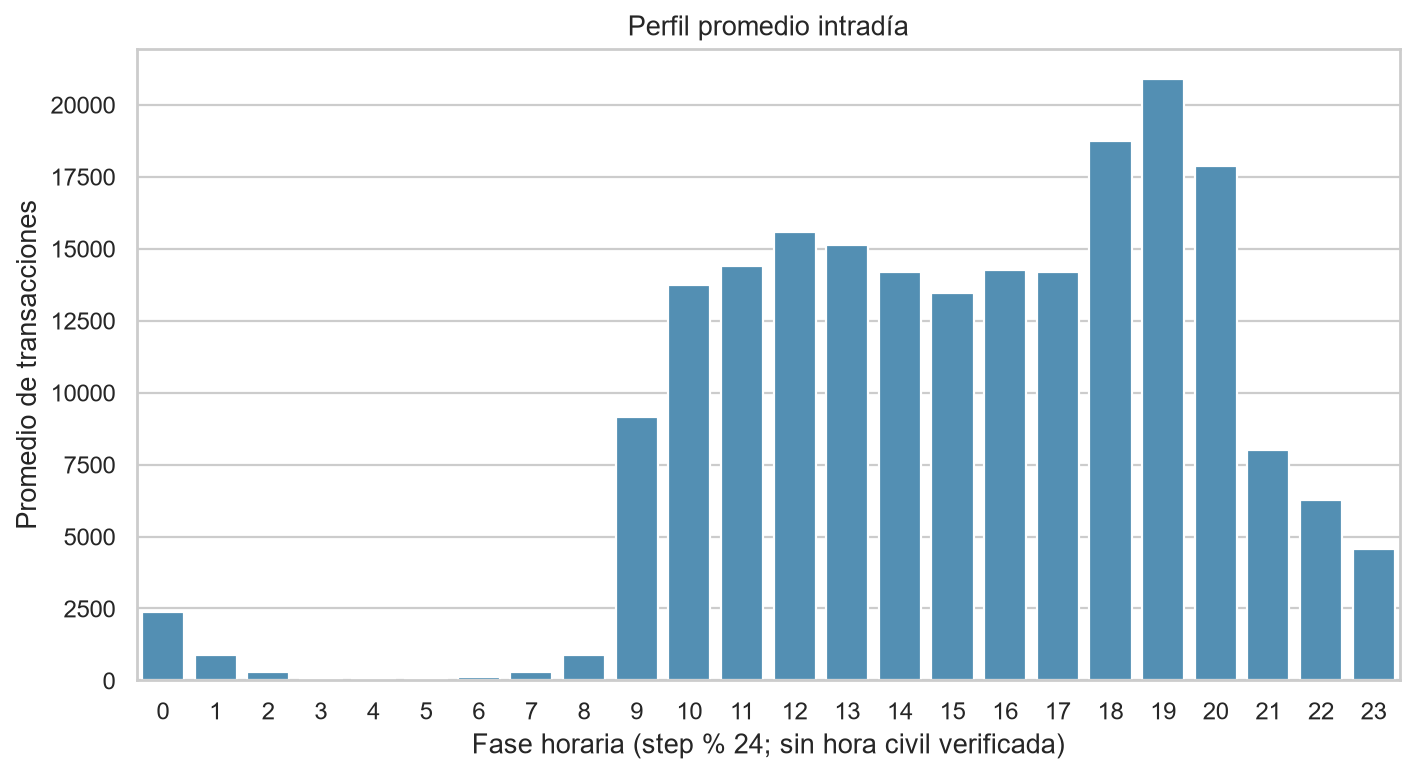

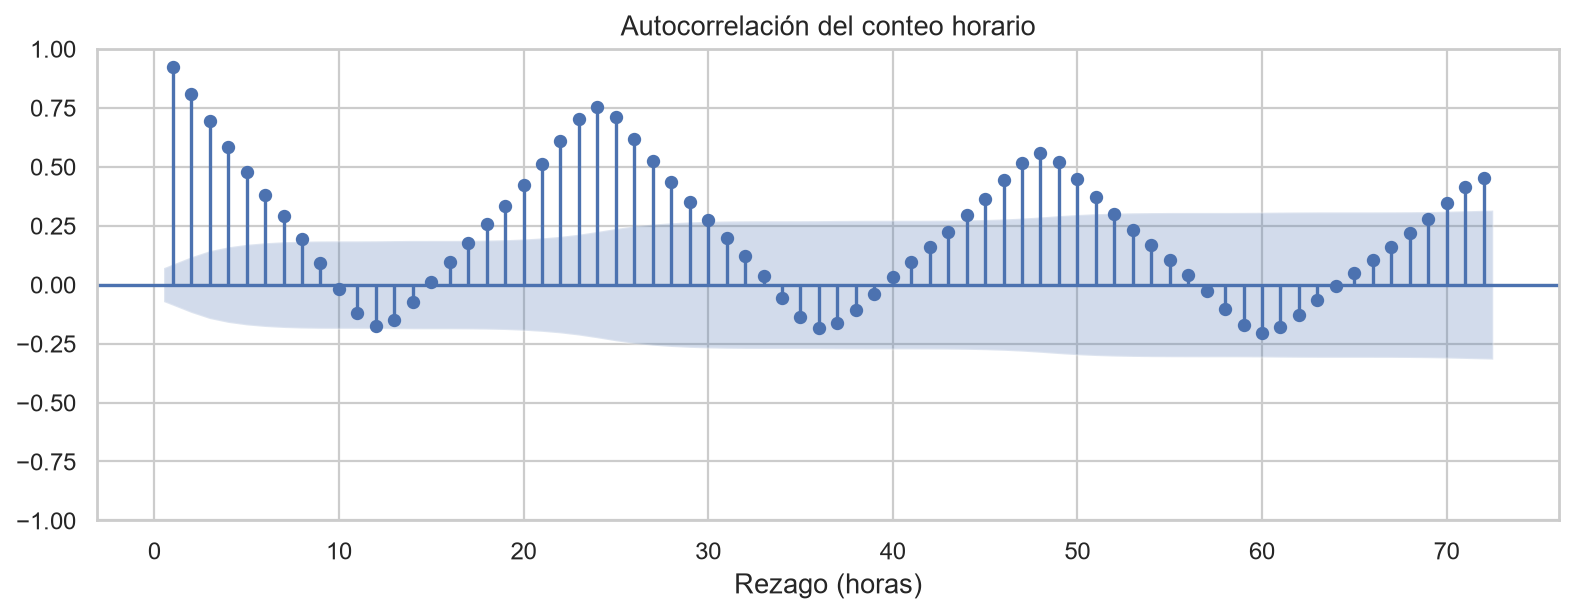

In [5]:
for name in ['serie_transacciones_hora.png','perfil_intradia.png','acf_conteo.png']:
    figura(name)

## Protocolo posterior de modelado

1. Ordenar la serie por step y reservar un bloque final.
2. Comparar ingenuo estacional y SARIMA con s=24.
3. Elegir transformación, d y D usando entrenamiento, inspección y pruebas; no usar todo el archivo para ajustar decisiones.
4. Evaluar ventanas cronológicas con MAE/RMSE.
5. Revisar residuos y Ljung-Box de residuos, no confundirlo con la prueba de la serie original.
6. Usar variables exógenas solo si se conocen al momento del pronóstico; rezagar los agregados de la misma hora.

## Entregable

El proyecto incluye código compartido, pruebas, app Streamlit, resultados, figuras, informe PDF/Markdown, referencias del curso y guía VSCode. Las métricas se vinculan al SHA-256 del archivo analizado. Los resultados se pueden consultar sin copiar el CSV grande; para recalcular hay que anexarlo en `data/` o indicar su ruta.